## 1. FASTA file import:

In [1]:
import proteosim_balint as ps
proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)


3

## 2. Protein digestion: 
### 2.1 Digest a single protein sequence with LysC



In [2]:
seq = proteins["P11802"]
cleave_pattern = ps.enzyme_cleavage_patterns['LysC']
print(ps.digest_protein_sequence(seq, cleave_pattern=cleave_pattern))

['MATSRYEPVAEIGVGAYGTVYK', 'ARDPHSGHFVALK', 'VTLVFEHVDQDLRTYLDK', 'APPPGLPAETIK', 'DLMRQFLRGLDFLHANCIVHRDLK', 'PENILVTSGGTVK', 'PLFCGNSEADQLGK', 'RISAFRALQHSYLHK', 'DEGNPE']


### 2.2 Digest a protein coleection with trypsin

In [3]:
cleave_pattern = ps.enzyme_cleavage_patterns['Trypsin']

digested_peptides_map = ps.digest_protein_collection(
    proteins,
    cleave_pattern=cleave_pattern,
    min_pep_len=5,
    max_pep_len=30,
)

digested_peptides_map

{'P11802': ['MATSR',
  'YEPVAEIGVGAYGTVYK',
  'DPHSGHFVALK',
  'VPNGGGGGGGLPISTVR',
  'EVALLR',
  'LEAFEHPNVVR',
  'LMDVCATSR',
  'VTLVFEHVDQDLR',
  'TYLDK',
  'APPPGLPAETIK',
  'GLDFLHANCIVHR',
  'DLKPENILVTSGGTVK',
  'LADFGLAR',
  'IYSYQMALTPVVVTLWYR',
  'APEVLLQSTYATPVDMWSVGCIFAEMFR',
  'KPLFCGNSEADQLGK',
  'IFDLIGLPPEDDWPR',
  'DVSLPR',
  'GAFPPR',
  'GPRPVQSVVPEMEESGAQLLLEMLTFNPHK',
  'ISAFR',
  'ALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK',
  'AVEILGNTEAAHPPSPIR',
  'CCWLR',
  'CLAATSIICGCSCLGVMALVFAIK',
  'SEEAVR'],
 'A0A087WTH5': ['MVIEWERPR',
  'MILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLAR',
  'SGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIR',
  'LEHSNDPFNVYIESNAWQEK',
  'AYVQAR',
  'VLESYR',
  'SCYVVENHLAIEQPNTHLPETKPSP']}

### 2.3 Calculate sequence coverage for _P11802_ using trypsin

In [4]:
seq = proteins["P11802"]
peps = digested_peptides_map["P11802"]
ps.compute_sequence_coverage(seq, peps)


92.73927392739274

## 3. Liquid chromatography
### 3.1 Predict LC retention times using the *pyteomics.achrom* model
The function needs a pooled list of peptides. First pool the sample peptides from above. 

In [5]:
pooled_peptides = []
for peptides in digested_peptides_map.values():
    for peptide in peptides: 
        pooled_peptides.append(peptide)
print(f'Total peptides: {len(pooled_peptides)}')

Total peptides: 37


In [6]:
rt_map = ps.predict_lc_retention_times(pooled_peptides)

rt_map

{'MATSR': 8.9,
 'YEPVAEIGVGAYGTVYK': 42.7,
 'DPHSGHFVALK': 29.0,
 'VPNGGGGGGGLPISTVR': 31.6,
 'EVALLR': 25.5,
 'LEAFEHPNVVR': 33.5,
 'LMDVCATSR': 23.6,
 'VTLVFEHVDQDLR': 41.0,
 'TYLDK': 11.1,
 'APPPGLPAETIK': 29.1,
 'GLDFLHANCIVHR': 47.5,
 'DLKPENILVTSGGTVK': 34.5,
 'LADFGLAR': 29.5,
 'IYSYQMALTPVVVTLWYR': 78.1,
 'APEVLLQSTYATPVDMWSVGCIFAEMFR': 96.2,
 'KPLFCGNSEADQLGK': 28.0,
 'IFDLIGLPPEDDWPR': 51.3,
 'DVSLPR': 14.7,
 'GAFPPR': 16.3,
 'GPRPVQSVVPEMEESGAQLLLEMLTFNPHK': 80.9,
 'ISAFR': 19.9,
 'ALQHSYLHK': 28.5,
 'DEGNPE': -4.0,
 'MEDEEK': -0.7,
 'AVEILGNTEAAHPPSPIR': 43.8,
 'CCWLR': 24.6,
 'CLAATSIICGCSCLGVMALVFAIK': 96.2,
 'SEEAVR': 5.7,
 'MVIEWERPR': 30.9,
 'MILSNTTAVTPFLTK': 51.1,
 'LWQETVQQGGNMSGLAR': 39.4,
 'SGDGK': -3.7,
 'LEALYVLMVLGFFGFFTLGIMLSYIR': 140.2,
 'LEHSNDPFNVYIESNAWQEK': 42.6,
 'AYVQAR': 15.6,
 'VLESYR': 18.4,
 'SCYVVENHLAIEQPNTHLPETKPSP': 54.2}

### 3.2 Plot retention times 


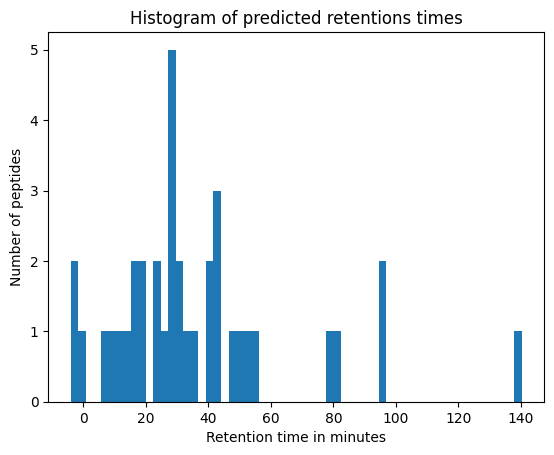

In [7]:
ps.plot_retention_time(rt_map.values(), resolution=60)

### 3.3 Select peptides that elute between 0 and 20 minutes

In [8]:
select_peps = ps.select_retention_time_window(
    peptide_rt_map=rt_map,
    lower_ret_time=0,
    upper_ret_time=20,
)

print(len(select_peps))
print(select_peps)

8
['MATSR', 'TYLDK', 'DVSLPR', 'GAFPPR', 'ISAFR', 'SEEAVR', 'AYVQAR', 'VLESYR']


## 4. Mass spectra simulation
### 4.1 Compute the molecular mass of a single peptide
Using the dummy sequence `PEPTIDE`

In [9]:
ps.calculate_mol_mass('PEPTIDE', ps.amino_acid_mass_dalton)


{'PEPTIDE': 781.84}

### 4.2 Calculate molecular masses for the selected peptides
Using the previous `select_peps` list.

In [10]:
mass_map_ms1 = ps.calculate_mol_mass_collection(select_peps, ps.amino_acid_mass_dalton)
mass_map_ms1

{'MATSR': 546.65,
 'TYLDK': 620.71,
 'DVSLPR': 667.77,
 'GAFPPR': 625.74,
 'ISAFR': 574.69,
 'SEEAVR': 671.72,
 'AYVQAR': 688.79,
 'VLESYR': 747.8599999999999}

### 4.3 Calculate m/z ratio for the selected peptides
Using the molecular masses computed in the previous step. 

In [11]:
mz1_map = ps.calculate_mz_collection(mass_map_ms1, charge=2)
mz1_map

{'MATSR': 274.332,
 'TYLDK': 311.362,
 'DVSLPR': 334.892,
 'GAFPPR': 313.877,
 'ISAFR': 288.35200000000003,
 'SEEAVR': 336.867,
 'AYVQAR': 345.402,
 'VLESYR': 374.93699999999995}

### 4.4 Plot a simulated MS1 spectrum
Using the m/z ratios calculated in the previous step and intensity values drawn randomly. 

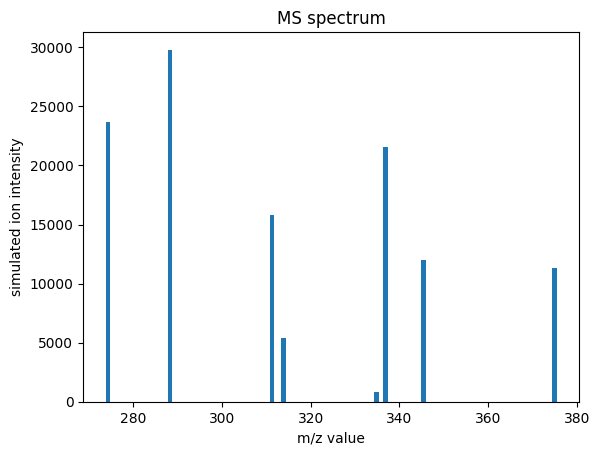

In [12]:
ps.plot_spectrum(mz1_map)

### 4.5 Fragment peptides into b- and y-ions and obtain the MS2 spectrum
Using the peptide sequence `MATSR`. 

### 4.5.1 Fragment the peptide



In [15]:
frags = ps.fragment_peptide('MATSR')
frags

['M', 'MA', 'MAT', 'MATS', 'R', 'SR', 'TSR', 'ATSR']

#### 4.5.2 Compute fragment masses

In [17]:
mass_map_ms2 = ps.calculate_mol_mass_collection(frags, ps.amino_acid_mass_dalton)
mass_map_ms2

{'M': 131.19,
 'MA': 202.26999999999998,
 'MAT': 303.38,
 'MATS': 390.46,
 'R': 156.19,
 'SR': 243.26999999999998,
 'TSR': 344.38,
 'ATSR': 415.46}

#### 4.5.3 Convert to m/z with `charge = +1`

In [18]:
mz2_map = ps.calculate_mz_collection(mass_map_ms2, charge=1)
mz2_map

{'M': 132.197,
 'MA': 203.277,
 'MAT': 304.387,
 'MATS': 391.467,
 'R': 157.197,
 'SR': 244.277,
 'TSR': 345.387,
 'ATSR': 416.467}

#### 4.5.4 Plot MS2 spectrum

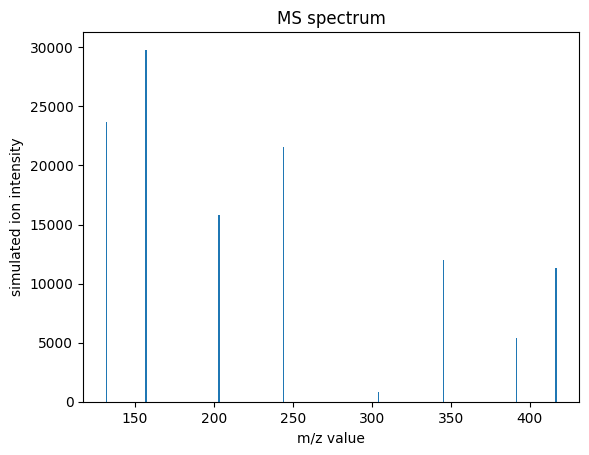

In [19]:
ps.plot_spectrum(mz2_map)